    Year_end             OlympiadType                    Subject  \
0       2014     Московская олимпиада  Изобразительное искусство   
23      2016     Московская олимпиада                     Физика   
25      2018  Всероссийская олимпиада        Физическая культура   

                  ShortName  Class  TeamSize      Status  Year_begin  
0           ГБОУ СОШ № 1188      2         3  победитель        2013  
23  ГАОУ ВО МИОО. СОШ № 179      9         4  победитель        2015  
25            ГКОУ КШИ № 11     11         5      призёр        2017  
Коэффициенты модели: [1.22688627e-16 2.00000000e+00], свободный член: 2007.0
[1.22688627e-16 2.00000000e+00]
Sklearn: w0=2007.000000, w1=0.000000, w2=2.000000
Backprop: w0=1044.848746, w1=-176.515701, w2=888.780564
Numdiff: w0=1044.848746, w1=-176.515701, w2=888.780564


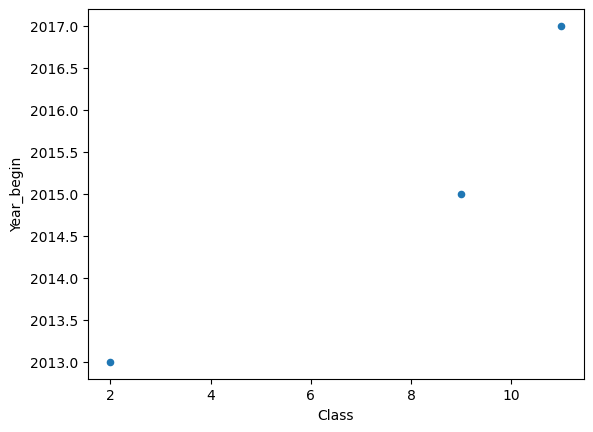

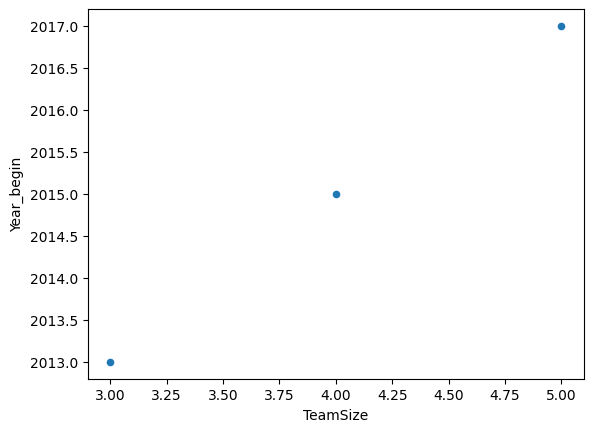

In [ ]:
from math import nan
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn import metrics
import numdifftools as nd

df = pd.read_csv('https://raw.githubusercontent.com/rvgarafutdinov/python_book_2023/main/lab7_datasets/dataset_12.csv')

X_cols = df[['Class', 'TeamSize']]
Y_col = df['Year_begin']

df_n = df.drop(index = list(range(1, 23)))
df_ne = df_n.drop(index = 24)
df_new = df_ne.drop(index = list(range(26, 559)))
print(df_new.head())

df_new.plot.scatter(x='Class', y='Year_begin')
df_new.plot.scatter(x='TeamSize', y='Year_begin')

X_train = df_new[['Class', 'TeamSize']].values
y_train = df_new['Year_begin'].values

model = LinearRegression()
model.fit(X=X_train, y=y_train)
print(f"Коэффициенты модели: {model.coef_}, свободный член: {model.intercept_}")

class CreateModel:
  def __init__(self):
        self.coef = None
        self.intercept = None
        self.weights = None
        self.w0 = 0
        self.w1 = 0
        self.w2 = 0

  def modelL(self, X):
        return (self.w0 + self.w1 * X[:, 0] + self.w2 * X[:, 1])
  def rmse(self, y_fact, y_pred):
        return ((sum((y_fact - y_pred) ** 2))/3)**0.5

  def backprop(self, X, y):
    n = 3
    y_pred = self.w0 + self.w1 * X[:, 0] + self.w2 * X[:, 1]
    E = y_pred - y
    rmse = ((sum((y - y_pred) ** 2))/3)**0.5

    dw0 = sum(E / (n * rmse) * 1)
    dw1 = sum(E / (n * rmse) * X[:, 0])
    dw2 = sum(E / (n * rmse) * X[:, 1])
    return np.array([dw0, dw1, dw2])

  def numdiff_gradient(self, X, y):
    def loss_function(weights):
        w0, w1, w2 = weights
        y_pred = w0 + w1 * X[:, 0] + w2 * X[:, 1]
        return ((sum((y - y_pred) ** 2)) / len(y)) ** 0.5
    return nd.Gradient(loss_function)([self.w0, self.w1, self.w2])

  def fit(self, X, y, h=0.01, max_iter=100, gamma=1, method='backprop'):
    a_start = np.array([0.0, 0.0, 0.0])

    for i in range(max_iter):
        if method == 'backprop':
            grad = self.backprop(X, y)
        else:
            grad = self.numdiff_gradient(X, y)

        a_start = gamma * a_start - h * grad
        self.w0 += a_start[0]
        self.w1 += a_start[1]
        self.w2 += a_start[2]
        y_pred = self.modelL(X)


    self.coef = np.array([self.w1, self.w2])
    self.intercept = self.w0
    return self

def predict(self, X):
    return self.modelL(X)

model_1 = CreateModel()

model_backprop = CreateModel()
model_backprop.fit(X_train, y_train, h=0.1, max_iter=1000, method='backprop')

model_numdiff = CreateModel()
model_numdiff.fit(X_train, y_train, h=0.1, max_iter=1000, method='numdifftools')
print(model.coef_)

print(f"Sklearn: w0={model.intercept_:.6f}, w1={model.coef_[0]:.6f}, w2={model.coef_[1]:.6f}")
print(f"Backprop: w0={model_backprop.w0:.6f}, w1={model_backprop.w1:.6f}, w2={model_backprop.w2:.6f}")
print(f"Numdiff: w0={model_numdiff.w0:.6f}, w1={model_numdiff.w1:.6f}, w2={model_numdiff.w2:.6f}")